# GeoLife outings EDA (T0)

Fixes the parameters of the outings pipeline (docs/geolife/PLAN_OUTINGS.md) from all 182 real users.
User ids are seeded-pseudonym free here: only integer codes appear, never real ids.

**Time convention.** GeoLife timestamps are GMT. Beijing local time is UTC+8 (no DST), so every
hour-of-day / weekday statistic below uses `t + 8h`. Whatever hour convention the DP artifact and
`generate/` use must be declared in the artifact; the synthetic render should draw local hours and
subtract 8 h only when it writes GMT-like timestamps.

**Ledger caveat.** Every choice informed by this notebook is *tuning on real data* and has to be listed in the
privacy ledger as unaccounted public-parameter selection (the final table says which).

In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "geolife").exists())
sys.path.insert(0, str(ROOT / "src"))
from geolife.inside import eda_outings as E, data as gd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# dataviz palette (light): categorical slots 1-4, sequential blue ramp, neutrals
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
CAT = [BLUE, ORANGE, AQUA, VIOLET]
INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.titleweight": "bold",
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": .6, "lines.linewidth": 1.6, "legend.frameon": False,
    "legend.fontsize": 8})

# ---- PUBLIC PARAMETERS (fixed here by reasoning, then checked against the numbers below) ----
GAP = 7200          # outing break (s)
DIST, DWELL = 200.0, 600.0     # stop rule: radius (m), dwell (s)
QUAL_DUR, QUAL_LEN = 300, 500  # a 'real' outing: >= 5 min and >= 500 m
MIN_OUT, MIN_DAYS = 10, 5      # min-activity rule: >= MIN_OUT real outings on >= MIN_DAYS local days
GAPS = [1800, 3600, 7200, 14400]
SEED = 20261101
print("local = UTC+8; GAP", GAP, "stop", DIST, "m /", DWELL, "s")

local = UTC+8; GAP 7200 stop 200.0 m / 600.0 s


In [2]:
t0 = time.time()
cands = [os.environ.get("GEOLIFE_POINTS", ""), str(ROOT / "geolife" / "inside" / "data" / "points.parquet"),
         "C:/Users/NaomiD/Documents/Projects/hackaton-2026/.claude/worktrees/agent-a04900ec477b059b7/geolife/data/points.parquet"]
cache = next((c for c in cands if c and Path(c).exists()), None)
assert cache, "points.parquet cache not found (set GEOLIFE_POINTS)"
raw = pd.read_parquet(cache)
print("raw points", f"{len(raw):,}", "users", raw.uid.nunique(), "files", raw.groupby(["uid", "traj"]).ngroups)
df = E.clean_points(raw); del raw
N_USERS = df.u.nunique()
print("clean points", f"{len(df):,}", "(dropped invalid coords, duplicate timestamps, isolated >70 m/s spikes)", f"{time.time()-t0:.0f}s")
U, T, LAT, LON = df.u.values, df.t.values, df.lat.values, df.lon.values
D, DT = E.step_dist_dt(U, T, LAT, LON)                    # step k joins point k and k+1
SAMEFILE = (df.traj.values[1:] == df.traj.values[:-1]) & (U[1:] == U[:-1])
HOUR, DOW = E.local_hour_dow(T)
print("local hour/dow check (first pt): hour", HOUR[0], "dow", DOW[0], "UTC", pd.to_datetime(T[0], unit="s"))
df["day"] = E.local_day(T)

raw points 24,876,978 users 182 files 18670


clean points 24,126,271 (dropped invalid coords, duplicate timestamps, isolated >70 m/s spikes) 30s


local hour/dow check (first pt): hour 10 dow 3 UTC 2008-10-23 02:53:04


## 1. Outing definition

An outing is a maximal run of one user's points with no time gap above the threshold, regardless of
file boundaries (consecutive files closer than the threshold merge; a long gap inside a file splits it).

files: 18670 | consecutive-file gaps (s) quantiles 10/25/50/75/90/99: [   2297.   23350.   40267.   59337.  134358. 1380073.]
  overlapping/abutting files (gap<=0): 0.000 | gap<=30s: 0.042 | <=30min: 0.090 | <=1h: 0.123 | <=2h: 0.164 | <=4h: 0.212 | >1 day: 0.148


within-file dt (s) quantiles 50/90/99/99.9: [  2.   5.  20. 604.]
  within-file gaps >    60s: 120,343  (6.45 per file)
  within-file gaps >   300s:  39,802  (2.13 per file)


  within-file gaps >  1800s:  11,853  (0.63 per file)
  within-file gaps >  3600s:   7,357  (0.39 per file)
  within-file gaps >  7200s:   4,114  (0.22 per file)


  within-file gaps > 14400s:   1,300  (0.07 per file)


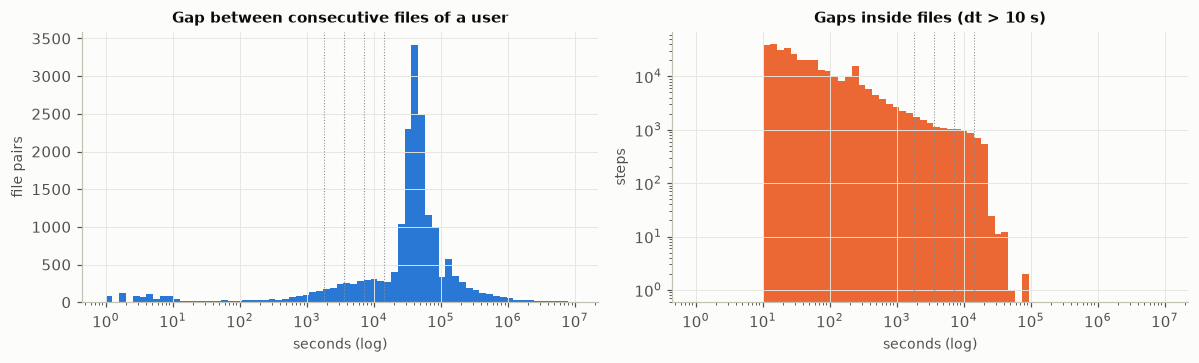

In [3]:
files = E.file_table(df)
g_prev = files.gap_prev.dropna().values
print("files:", len(files), "| consecutive-file gaps (s) quantiles 10/25/50/75/90/99:", np.percentile(g_prev, [10, 25, 50, 75, 90, 99]).round(0))
print("  overlapping/abutting files (gap<=0): %.3f | gap<=30s: %.3f | <=30min: %.3f | <=1h: %.3f | <=2h: %.3f | <=4h: %.3f | >1 day: %.3f" % (
      (g_prev <= 0).mean(), (g_prev <= 30).mean(), (g_prev <= 1800).mean(), (g_prev <= 3600).mean(), (g_prev <= 7200).mean(), (g_prev <= 14400).mean(), (g_prev > 86400).mean()))
wd = DT[SAMEFILE]
print("within-file dt (s) quantiles 50/90/99/99.9:", np.percentile(wd, [50, 90, 99, 99.9]))
nf_user = files.groupby("u").size()
for thr in (60, 300, 1800, 3600, 7200, 14400):
    print(f"  within-file gaps > {thr:>5}s: {(wd > thr).sum():>7,}  ({(wd>thr).sum()/files.shape[0]:.2f} per file)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
lb = np.logspace(0, 7, 70)
ax[0].hist(g_prev[g_prev > 0], bins=lb, color=BLUE); ax[0].set_xscale("log")
ax[0].set(title="Gap between consecutive files of a user", xlabel="seconds (log)", ylabel="file pairs")
ax[1].hist(wd[wd > 10], bins=lb, color=ORANGE); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set(title="Gaps inside files (dt > 10 s)", xlabel="seconds (log)", ylabel="steps")
for a in ax:
    for v, l in ((1800, "30m"), (3600, "1h"), (7200, "2h"), (14400, "4h")): a.axvline(v, color="#8a8f98", lw=.7, ls=":")
plt.tight_layout(); plt.show()

In [4]:
# labels -> per-point mode code (labelled subset: 69 users)
MODEMAP = {"walk": "walk", "run": "walk", "bike": "bike", "bus": "bus", "car": "car/taxi", "taxi": "car/taxi",
           "train": "rail", "subway": "rail", "railway": "rail", "airplane": "other", "boat": "other", "motorcycle": "other"}
MODES = ["walk", "bike", "bus", "car/taxi", "rail", "other"]
data_root = gd.default_data_dir()
umap = df.groupby("uid").u.first()
rows = []
for ud in sorted((data_root / "Data").iterdir()):
    lp = ud / "labels.txt"
    if lp.exists() and ud.name in umap.index:
        for s in gd.read_labels(lp): rows.append((umap[ud.name], s.t_start, s.t_end, MODEMAP.get(s.mode, "other")))
lab = pd.DataFrame(rows, columns=["u", "t0", "t1", "mode"]).sort_values(["u", "t0"]).reset_index(drop=True)
K0 = lab.u.values.astype(np.int64) * 10**10 + lab.t0.values
idx = np.searchsorted(K0, U.astype(np.int64) * 10**10 + T, side="right") - 1
idc = np.clip(idx, 0, None)
okl = (idx >= 0) & (lab.u.values[idc] == U) & (T <= lab.t1.values[idc])
MODECODE = np.where(okl, pd.Categorical(lab["mode"], categories=MODES).codes[idc], -1).astype(np.int8)
print("labelled users", lab.u.nunique(), "segments", len(lab), "| labelled points %.3f" % okl.mean())

labelled users 69 segments 14718 | labelled points 0.201


  gap  outings  real(>=5min,>=500m)  share_real  med_dur_min  p90_dur_min  med_len_km  p90_len_km  med_pts  multi_file_share  users>=10_real  med_real/user  p90/user  max/user  top10%users_share
 1800    28862                26014       0.901         31.2        134.0        5.22        30.2      396             0.045             147           37.0     364.6      2846              0.596
 3600    23762                22159       0.933         37.7        195.0        7.03        37.5      449             0.067             143           33.0     292.2      2590              0.597
 7200    19746                18743       0.949         44.6        302.0        8.99        46.5      509             0.095             139           29.5     254.2      2312              0.593
14400    16059                15385       0.958         57.0        532.0       11.41        61.5      592             0.130             130           26.0     190.3      1990              0.585


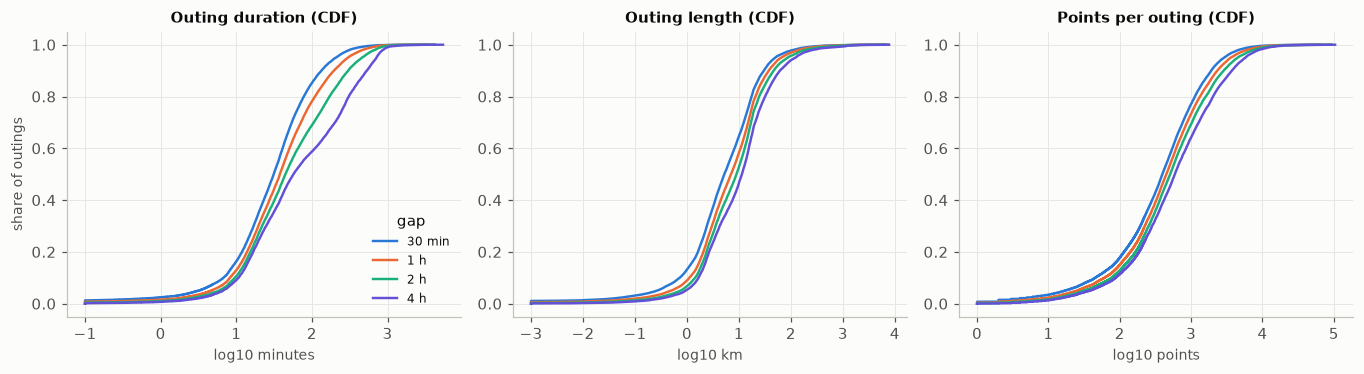

In [5]:
O = {}
rows = []
for g in GAPS:
    oid = E.outing_ids(U, T, g)
    o = E.outing_table(df, oid, D)
    o["dur_min"] = (o.t1 - o.t0) / 60; o["len_km"] = o.len_m / 1000
    o["qual"] = (o.dur_min * 60 >= QUAL_DUR) & (o.len_m >= QUAL_LEN)
    o["day"] = E.local_day(o.t0.values)
    O[g] = (oid, o)
    per_user = o[o.qual].groupby("u").size().reindex(range(N_USERS)).fillna(0)
    rows.append({"gap": g, "outings": len(o), "real(>=5min,>=500m)": int(o.qual.sum()), "share_real": round(o.qual.mean(), 3),
                 "med_dur_min": o.dur_min.median().round(1), "p90_dur_min": o.dur_min.quantile(.9).round(0),
                 "med_len_km": o.len_km.median().round(2), "p90_len_km": o.len_km.quantile(.9).round(1),
                 "med_pts": int(o.n.median()), "multi_file_share": round((o.nfiles > 1).mean(), 3),
                 "users>=10_real": int((per_user >= 10).sum()), "med_real/user": per_user.median(), "p90/user": per_user.quantile(.9), "max/user": int(per_user.max()),
                 "top10%users_share": round(per_user.sort_values(ascending=False).head(N_USERS // 10).sum() / per_user.sum(), 3)})
print(pd.DataFrame(rows).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
for g, c in zip(GAPS, CAT):
    o = O[g][1]; lbl = {1800: "30 min", 3600: "1 h", 7200: "2 h", 14400: "4 h"}[g]
    for a, v, rng in ((ax[0], o.dur_min.clip(lower=.1), (-1, 3.5)), (ax[1], o.len_km.clip(lower=.001), (-3, 3.5)), (ax[2], o.n.clip(lower=1), (0, 6.5))):
        x = np.sort(np.log10(v.values)); a.plot(x, np.arange(1, len(x) + 1) / len(x), color=c, label=lbl)
ax[0].set(title="Outing duration (CDF)", xlabel="log10 minutes", ylabel="share of outings")
ax[1].set(title="Outing length (CDF)", xlabel="log10 km"); ax[2].set(title="Points per outing (CDF)", xlabel="log10 points")
ax[0].legend(title="gap", loc="lower right"); plt.tight_layout(); plt.show()

In [6]:
# mode on the labelled subset, chosen gap
oid_g, og = O[GAP]
mode, share = E.mode_per_outing(oid_g, MODECODE, len(og), len(MODES))
og["mode"] = mode; og["mode_share"] = share
lo = og[og["mode"] >= 0]
print("outings with >=50%% labelled points: %d of %d (%.3f); dominant-mode share median %.2f, share pure(>=0.8): %.3f" % (
      len(lo), len(og), len(lo) / len(og), lo.mode_share.median(), (lo.mode_share >= .8).mean()))
tab = lo.assign(m=[MODES[i] for i in lo["mode"]]).groupby("m").agg(outings=("n", "size"), users=("u", "nunique"),
        med_dur_min=("dur_min", "median"), med_len_km=("len_km", "median"), p90_len_km=("len_km", lambda s: s.quantile(.9))).round(2)
print(tab.sort_values("outings", ascending=False))

outings with >=50% labelled points: 4197 of 19746 (0.213); dominant-mode share median 1.00, share pure(>=0.8): 0.709
          outings  users  med_dur_min  med_len_km  p90_len_km
m                                                            
walk         1158     54        38.79        3.99       27.55
bike         1037     28        22.17        3.84       10.98
bus           834     38        65.74       12.88       41.42
car/taxi      794     36        43.93       18.62       59.82
rail          368     23        44.46       18.44      217.34
other           6      2        25.62        2.94     1576.47


              min  10%   25%   50%    75%    90%     99%     max
real_outings  1.0  4.0  10.0  29.5   94.8  254.2  1073.8  2312.0
real_days     1.0  3.0   6.0  19.0   59.5  125.5   617.1  1232.0
active_days   1.0  4.0   7.0  21.5   63.0  133.3   627.3  1251.0
span_days     1.0  5.1  11.0  71.5  168.2  363.9  1616.8  4591.0
active-day density (active_days/span) median: 0.52
min_days           2    3    5    10
min_real_outings                    
3                 174  166  153  121
5                 159  159  153  121
10                139  139  139  121
20                109  109  109  109
30                 91   91   91   91
CHOSEN rule: >= 10 real outings on >= 5 local days -> 139 users; keeps 0.990 of real outings


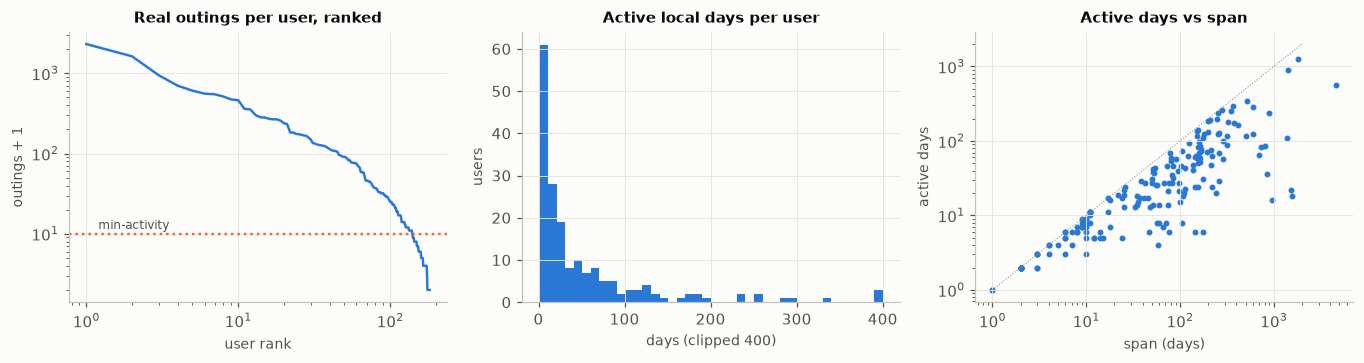

In [7]:
# per-user: outings, active days, span (chosen gap)
df["oid"] = oid_g
th = E.thin_30s(df)                                    # 30 s thinning (first point per user per 30 s)
days = th.groupby("u").day.agg(active_days="nunique", first="min", last="max")
days["span_days"] = days["last"] - days["first"] + 1
q = og[og.qual]
uq = pd.DataFrame({"real_outings": q.groupby("u").size(), "real_days": q.groupby("u").day.nunique()}).reindex(range(N_USERS)).fillna(0)
uq = uq.join(days[["active_days", "span_days"]]).fillna(0)
print(uq.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1).T[["min", "10%", "25%", "50%", "75%", "90%", "99%", "max"]])
print("active-day density (active_days/span) median: %.2f" % (uq.active_days / uq.span_days.clip(lower=1)).median())
rule = []
for mo in (3, 5, 10, 20, 30):
    for md_ in (2, 3, 5, 10):
        ok = (uq.real_outings >= mo) & (uq.real_days >= md_)
        rule.append({"min_real_outings": mo, "min_days": md_, "users": int(ok.sum()), "share_real_outings_kept": round(q.u.isin(uq.index[ok]).mean(), 3)})
print(pd.DataFrame(rule).pivot(index="min_real_outings", columns="min_days", values="users"))
QU = uq.index[(uq.real_outings >= MIN_OUT) & (uq.real_days >= MIN_DAYS)].values
print(f"CHOSEN rule: >= {MIN_OUT} real outings on >= {MIN_DAYS} local days -> {len(QU)} users; keeps {q.u.isin(QU).mean():.3f} of real outings")
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
s = uq.real_outings.sort_values(ascending=False).values
ax[0].plot(np.arange(1, len(s) + 1), s + 1, color=BLUE); ax[0].set_yscale("log"); ax[0].set_xscale("log")
ax[0].set(title="Real outings per user, ranked", xlabel="user rank", ylabel="outings + 1"); ax[0].axhline(MIN_OUT, color=ORANGE, ls=":"); ax[0].text(1.2, MIN_OUT * 1.15, "min-activity", color=INK2, fontsize=8)
ax[1].hist(uq.active_days.clip(upper=400), bins=40, color=BLUE); ax[1].set(title="Active local days per user", xlabel="days (clipped 400)", ylabel="users")
ax[2].scatter(uq.span_days.clip(lower=1), uq.active_days.clip(lower=1), s=8, color=BLUE); ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].plot([1, 2000], [1, 2000], color="#8a8f98", lw=.7, ls=":"); ax[2].set(title="Active days vs span", xlabel="span (days)", ylabel="active days")
plt.tight_layout(); plt.show()

## 2. Stops

Stop = Li et al. stay-point (distance radius around an anchor, minimum dwell), run on points thinned to one
per 30 s and segmented by outing (a stop never spans an outing break). Dwell ends only where the log
ends: an outing that ends *at* a destination yields no stop for it (start/end places are separate visits
in the pipeline, T1).

In [8]:
X, Y = E.to_xy(th.lat.values, th.lon.values)
TT = th.t.values.astype(float); OID_T = th.oid.values
n_out = len(og)
def stays_for(dist, dwell):
    i0, i1, mx, my, rms = E.detect_stays(X, Y, TT, OID_T, dist, dwell)
    la, lo = E.from_xy(mx, my)
    return pd.DataFrame({"u": th.u.values[i0], "oid": OID_T[i0], "t0": th.t.values[i0], "t1": th.t.values[i1],
                         "lat": la, "lon": lo, "rms": rms, "npts": i1 - i0 + 1})
def revisit_rate(st, cells):
    k = pd.DataFrame({"u": st.u.values, "c": cells, "o": st.oid.values})
    first = k.groupby(["u", "c"]).o.transform("min")
    return float((k.o > first).mean())
rows, ST = [], {}
qual_oid = og.index[og.qual & og.u.isin(QU)].values
for dist in (100, 200, 300):
    for dwell in (300, 600, 1200):
        st = stays_for(dist, dwell); ST[(dist, dwell)] = st
        cs = E.h3_cells(st.lat.values, st.lon.values, (8, 9, 10))
        cnt = np.bincount(st.oid.values, minlength=n_out)[qual_oid]
        r = {"dist_m": dist, "dwell_min": dwell // 60, "stops": len(st), "users_with_stop": st.u.nunique(),
             "stops/real_outing": round(cnt.mean(), 2), "outings>=1": round((cnt >= 1).mean(), 3), "outings>=2": round((cnt >= 2).mean(), 3),
             "med_dwell_min": round(((st.t1 - st.t0) / 60).median(), 1)}
        for res in (8, 9, 10): r[f"revisit_r{res}"] = round(revisit_rate(st, cs[res]), 3)
        sq = st[st.u.isin(QU)]; csq = E.h3_cells(sq.lat.values, sq.lon.values, (8, 9))
        for res in (8, 9):
            r[f"places/user_r{res}"] = pd.Series(csq[res]).groupby(sq.u.values).nunique().median()
        rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

 dist_m  dwell_min  stops  users_with_stop  stops/real_outing  outings>=1  outings>=2  med_dwell_min  revisit_r8  revisit_r9  revisit_r10  places/user_r8  places/user_r9
    100          5  38841              180               2.05       0.549       0.336           10.9       0.604       0.522        0.428            29.0            45.0
    100         10  22413              175               1.18       0.416       0.233           21.0       0.591       0.507        0.422            21.5            29.5
    100         20  12700              169               0.67       0.312       0.149           38.5       0.589       0.511        0.432            14.0            18.0
    200          5  45653              180               2.41       0.660       0.413           10.5       0.621       0.533        0.418            35.0            54.0
    200         10  26043              178               1.38       0.487       0.274           22.5       0.594       0.501        0.393            2

CHOSEN stop rule 200.0 m / 10.0 min: 26043 stops; stops per real outing (QU users) p50/p90/p99/max: [ 0.  4. 12. 33.]
stop dwell (min) quantiles 10/50/90/99: [11.0, 22.5, 90.0, 227.6]


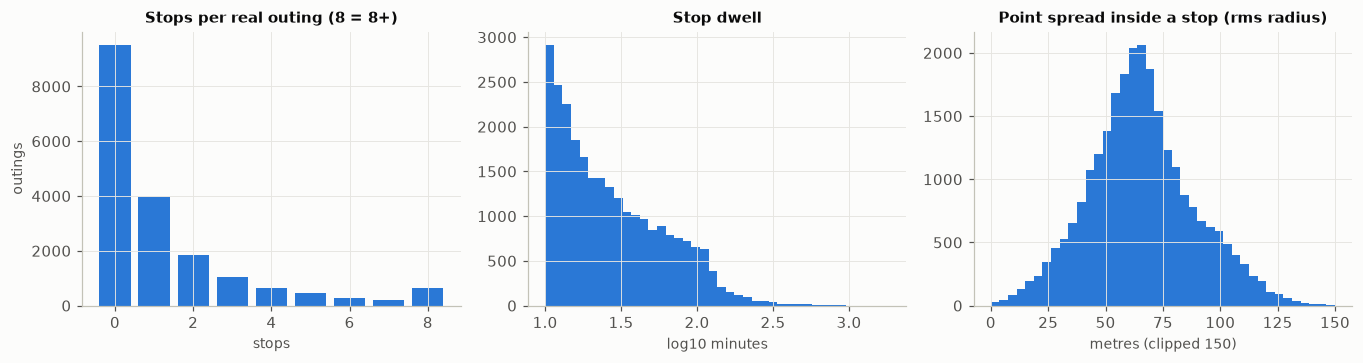

jitter proxy: rms radius of 30s-thinned points around stop centre (m) quantiles 10/50/90: [37.0, 64.3, 97.2]


In [9]:
st = ST[(int(DIST), int(DWELL))]
cnt = np.bincount(st.oid.values, minlength=n_out)[qual_oid]
print("CHOSEN stop rule", DIST, "m /", DWELL // 60, "min:", len(st), "stops;", "stops per real outing (QU users) p50/p90/p99/max:", np.percentile(cnt, [50, 90, 99, 100]))
print("stop dwell (min) quantiles 10/50/90/99:", (((st.t1 - st.t0) / 60).quantile([.1, .5, .9, .99])).round(1).tolist())
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].bar(*np.unique(np.minimum(cnt, 8), return_counts=True), color=BLUE); ax[0].set(title="Stops per real outing (8 = 8+)", xlabel="stops", ylabel="outings")
ax[1].hist(np.log10(((st.t1 - st.t0) / 60).clip(lower=1)), bins=40, color=BLUE); ax[1].set(title="Stop dwell", xlabel="log10 minutes")
ax[2].hist(st.rms.clip(upper=150), bins=40, color=BLUE); ax[2].set(title="Point spread inside a stop (rms radius)", xlabel="metres (clipped 150)")
plt.tight_layout(); plt.show()
print("jitter proxy: rms radius of 30s-thinned points around stop centre (m) quantiles 10/50/90:", st.rms.quantile([.1, .5, .9]).round(1).tolist())

## 3. Time structure (local = UTC+8)

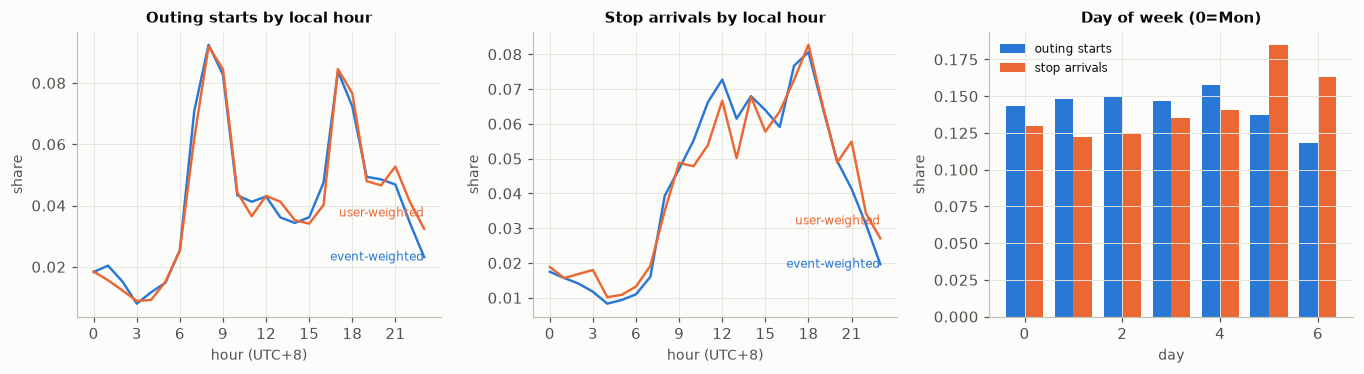

weekend share (Sat+Sun, 2/7 = .286 if flat): outing starts 0.255  stops 0.347
outing starts 4 time-of-day bins (night 0-6, morning 6-12, afternoon 12-18, evening 18-24): [0.088 0.356 0.281 0.275]
stop arrivals 4 time-of-day bins (night 0-6, morning 6-12, afternoon 12-18, evening 18-24): [0.077 0.235 0.402 0.287]


In [10]:
stl = st.copy()
stl["hour"], stl["dow"] = E.local_hour_dow(stl.t0.values)
og["hour"], og["dow"] = E.local_hour_dow(og.t0.values)
def user_weighted_hist(user, val, bins):
    h = pd.crosstab(user, pd.Categorical(val, categories=range(bins))).values.astype(float)
    h = h[h.sum(1) > 0]; return (h / h.sum(1, keepdims=True)).mean(0)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
qo = og[og.qual & og.u.isin(QU)]; qs = stl[stl.u.isin(QU)]
for a, d_, ttl in ((ax[0], qo, "Outing starts"), (ax[1], qs, "Stop arrivals")):
    ev = np.bincount(d_.hour.astype(int), minlength=24) / len(d_)
    uw = user_weighted_hist(d_.u.values, d_.hour.astype(int).values, 24)
    a.plot(range(24), ev, color=BLUE); a.plot(range(24), uw, color=ORANGE)
    a.text(23, ev[-1], " event-weighted", color=BLUE, fontsize=8, va="center", ha="right"); a.text(23, uw[-1] + .004, "user-weighted", color=ORANGE, fontsize=8, ha="right")
    a.set(title=ttl + " by local hour", xlabel="hour (UTC+8)", ylabel="share"); a.set_xticks(range(0, 24, 3))
wk = lambda dw: (dw >= 5).astype(int)
dd = pd.DataFrame({"Outing starts": np.bincount(qo.dow.astype(int), minlength=7) / len(qo), "Stop arrivals": np.bincount(qs.dow.astype(int), minlength=7) / len(qs)})
w = .38
ax[2].bar(np.arange(7) - w / 2, dd["Outing starts"], w, color=BLUE, label="outing starts"); ax[2].bar(np.arange(7) + w / 2, dd["Stop arrivals"], w, color=ORANGE, label="stop arrivals")
ax[2].set(title="Day of week (0=Mon)", xlabel="day", ylabel="share"); ax[2].legend()
plt.tight_layout(); plt.show()
print("weekend share (Sat+Sun, 2/7 = .286 if flat): outing starts %.3f  stops %.3f" % (wk(qo.dow.values).mean(), wk(qs.dow.values).mean()))
for nm, d_ in (("outing starts", qo), ("stop arrivals", qs)):
    print(nm, "4 time-of-day bins (night 0-6, morning 6-12, afternoon 12-18, evening 18-24):", (np.bincount(E.tod_bin4(d_.hour.values.astype(int)), minlength=4) / len(d_)).round(3))

 cell_r7_rank  users  stops  JSD_vs_overall  JSD_if_random_same_size  ratio  night%  morning%  afternoon%  evening%  weekend%
            1    112   2070          0.0161                   0.0007   24.6       9        23          32        36        26
            2    108   1518          0.0053                   0.0009    6.1       7        24          39        30        27
            3     73   1522          0.0114                   0.0008   13.7       4        20          41        35        29
            4     71    563          0.0086                   0.0022    3.9       8        23          37        32        29
            5     57   1001          0.0060                   0.0013    4.7       5        23          46        26        34
            6     46    115          0.0604                   0.0117    5.2       9        28          29        35        43
            7     46    151          0.0194                   0.0085    2.3      11        15          39        35   

places table: 7401 places; stops snapped within 150 m: 0.483 (coverage of the public table, not of reality)
category  stops  users    JSD  noise_JSD  ratio
    food   3723    127 0.0055     0.0004   15.5
  school   2144    100 0.0131     0.0006   21.3
  office   1427    105 0.0168     0.0009   18.2
 leisure   1423    116 0.0047     0.0009    5.2
   other   1268    109 0.0038     0.0010    3.7
    shop   1236    104 0.0121     0.0011   11.2
 transit    982     99 0.0097     0.0013    7.2
  health    176     47 0.0255     0.0074    3.5


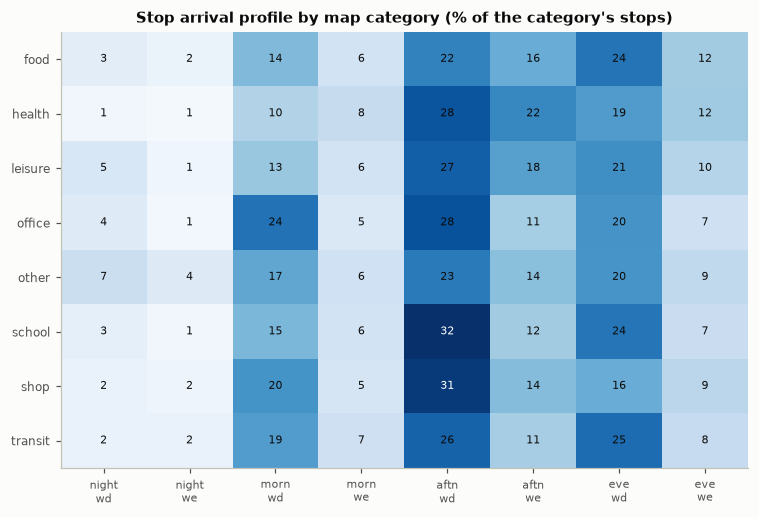

In [11]:
# distinctness of profiles: top coarse cells and map categories vs the overall 8-bin (4 tod x wd/we) profile
def bin8(hour, dow): return E.tod_bin4(np.asarray(hour).astype(int)) * 2 + (np.asarray(dow) >= 5)
qs = qs.copy(); qs["b8"] = bin8(qs.hour, qs.dow)
qs["c7"] = E.h3_cells(qs.lat.values, qs.lon.values, (7,))[7]
overall = np.bincount(qs.b8, minlength=8).astype(float)
rng = np.random.default_rng(SEED)
def noise_jsd(n, reps=200):
    return np.mean([E.js_divergence(np.bincount(rng.choice(qs.b8.values, n), minlength=8) + 1e-9, overall) for _ in range(reps)])
nu = qs.groupby("c7").u.nunique().sort_values(ascending=False)
rows = []
for c in nu.index[:8]:
    s_ = qs[qs.c7 == c]; p = np.bincount(s_.b8, minlength=8)
    j = E.js_divergence(p + 1e-9, overall); nj = noise_jsd(len(s_))
    rows.append({"cell_r7_rank": len(rows) + 1, "users": nu[c], "stops": len(s_), "JSD_vs_overall": round(j, 4), "JSD_if_random_same_size": round(nj, 4), "ratio": round(j / nj, 1),
                 "night%": round(100 * p[0:2].sum() / p.sum()), "morning%": round(100 * p[2:4].sum() / p.sum()), "afternoon%": round(100 * p[4:6].sum() / p.sum()), "evening%": round(100 * p[6:8].sum() / p.sum()), "weekend%": round(100 * p[1::2].sum() / p.sum())})
print(pd.DataFrame(rows).to_string(index=False))
# map categories (public places table, optional) - snap stop centres within 150 m
pp = next((p for p in [str(ROOT / "geolife" / "outside" / "cache" / "places_beijing_big.parquet"), "C:/Users/NaomiD/Documents/Projects/hackaton-2026/.claude/worktrees/agent-a63109956b0e67a7c/geolife/cache/places_beijing_big.parquet"] if Path(p).exists()), None)
cat_prof = None
if pp:
    from scipy.spatial import cKDTree
    pl = pd.read_parquet(pp); px, py = E.to_xy(pl.lat.values, pl.lon.values); tree = cKDTree(np.c_[px, py])
    sx, sy = E.to_xy(qs.lat.values, qs.lon.values); dd_, ii = tree.query(np.c_[sx, sy], distance_upper_bound=150)
    hit = np.isfinite(dd_); qs["cat"] = np.where(hit, pl.category.values[np.minimum(ii, len(pl) - 1)], None)
    print("places table:", len(pl), "places;", "stops snapped within 150 m: %.3f" % hit.mean(), "(coverage of the public table, not of reality)")
    rows = []
    for cname, s_ in qs[hit].groupby("cat"):
        if len(s_) < 150: continue
        p = np.bincount(s_.b8, minlength=8); j = E.js_divergence(p + 1e-9, overall); nj = noise_jsd(len(s_))
        rows.append({"category": cname, "stops": len(s_), "users": s_.u.nunique(), "JSD": round(j, 4), "noise_JSD": round(nj, 4), "ratio": round(j / nj, 1)})
    cat_prof = pd.DataFrame(rows).sort_values("stops", ascending=False); print(cat_prof.to_string(index=False))
    heat = qs[hit].groupby(["cat", "b8"]).size().unstack(fill_value=0)
    heat = heat[heat.sum(1) >= 150]; heat = heat.div(heat.sum(1), axis=0)
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(heat) + 1.2))
    im = ax.imshow(heat.values, aspect="auto", cmap="Blues", vmin=0)
    ax.set_xticks(range(8)); ax.set_xticklabels([f"{n}\n{w_}" for n in ("night", "morn", "aftn", "eve") for w_ in ("wd", "we")], fontsize=7)
    ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index, fontsize=8); ax.grid(False)
    for i in range(heat.shape[0]):
        for j in range(8): ax.text(j, i, f"{100*heat.values[i,j]:.0f}", ha="center", va="center", fontsize=7, color=INK if heat.values[i, j] < .3 else "white")
    ax.set_title("Stop arrival profile by map category (% of the category's stops)"); plt.tight_layout(); plt.show()
else:
    print("places table not available; category profiles skipped")

In [12]:
# do finer time bins survive user-level counts?  distinct users per (res-7 cell, time bin)
schemes = {"1 (none)": lambda h, d: np.zeros(len(h), int), "2 (wd/we)": lambda h, d: (d >= 5).astype(int), "4 tod": lambda h, d: h // 6,
           "8 (4 tod x wd/we)": lambda h, d: (h // 6) * 2 + (d >= 5), "12 (4h x wd/we)": lambda h, d: (h // 4) * 2 + (d >= 5),
           "24 hours": lambda h, d: h, "48 (24h x wd/we)": lambda h, d: h * 2 + (d >= 5)}
h_, d_ = qs.hour.values.astype(int), qs.dow.values
rows = []
for nm, f in schemes.items():
    b = f(h_, d_); k = pd.DataFrame({"u": qs.u.values, "c": qs.c7.values, "b": b}).drop_duplicates()
    nuc = k.groupby(["c", "b"]).u.transform("nunique")
    ncells = k.groupby(["c", "b"]).ngroups
    rows.append({"bins": nm, "(cell,bin) keys": ncells, "keys>=10 users": int((k.groupby(["c", "b"]).u.nunique() >= 10).sum()),
                 "share user-keys in >=10-user keys": round(float((nuc >= 10).mean()), 3), "share in >=5-user keys": round(float((nuc >= 5).mean()), 3),
                 "stops/bin (median over bins)": int(pd.Series(b).value_counts().median())})
print(pd.DataFrame(rows).to_string(index=False))
print("stops (QU users):", len(qs), " users:", qs.u.nunique())

             bins  (cell,bin) keys  keys>=10 users  share user-keys in >=10-user keys  share in >=5-user keys  stops/bin (median over bins)
         1 (none)             1774              79                              0.407                   0.514                         25620
        2 (wd/we)             2227             100                              0.377                   0.503                         12810
            4 tod             2912             121                              0.341                   0.489                          6679
8 (4 tod x wd/we)             3619             116                              0.278                   0.440                          3128
  12 (4h x wd/we)             4182             117                              0.249                   0.422                          2063
         24 hours             5984             135                              0.211                   0.379                          1132
 48 (24h x wd/we)   

## 4. Overlap (co-visit)

Cells are H3 at res 6-9. *Stops* = stop centres; *trajectory cells* = every cell traversed (a road proxy;
positions rounded to 1e-4 deg, about 11 m, before cell lookup). Only users passing the min-activity rule.
`core` = lat 39.8-40.1, lon 116.2-116.6 (Haidian / 3rd ring), everything else is `all`.

In [13]:
t1 = time.time()
RES = (6, 7, 8, 9)
CELLS = E.h3_cells(LAT, LON, RES)
print("trajectory cells computed", f"{time.time()-t1:.0f}s")
core_pt = (LAT >= E.CORE_BOX[0]) & (LAT <= E.CORE_BOX[1]) & (LON >= E.CORE_BOX[2]) & (LON <= E.CORE_BOX[3])
u_of_oid = og.u.values
INC = {}   # (kind,res,scope) -> DataFrame(oid, cell)
for r in RES:
    INC[("traj", r, "all")] = E.incidence(CELLS[r], oid_g)
    INC[("traj", r, "core")] = E.incidence(CELLS[r], oid_g, core_pt)
CELLS = None
stq = st.copy(); stq["hour"], stq["dow"] = E.local_hour_dow(stq.t0.values)
stc = E.h3_cells(stq.lat.values, stq.lon.values, RES + (10,))
core_st = (stq.lat.values >= E.CORE_BOX[0]) & (stq.lat.values <= E.CORE_BOX[1]) & (stq.lon.values >= E.CORE_BOX[2]) & (stq.lon.values <= E.CORE_BOX[3])
for r in RES + (10,):
    INC[("stop", r, "all")] = pd.DataFrame({"oid": stq.oid.values, "cell": stc[r]}).drop_duplicates()
    INC[("stop", r, "core")] = pd.DataFrame({"oid": stq.oid.values[core_st], "cell": stc[r][core_st]}).drop_duplicates()
# restrict to users passing the activity rule; incidence by USER
QSET = set(QU.tolist())
def by_user(inc):
    x = inc.assign(u=u_of_oid[inc.oid.values]); x = x[x.u.isin(QSET)]
    return x[["u", "cell"]].drop_duplicates().reset_index(drop=True)
UC = {k: by_user(v) for k, v in INC.items()}
print(f"{time.time()-t1:.0f}s; users in play: {len(QU)}")
rows = []
for (kind, r, scope), uc in UC.items():
    if r == 10 and kind == "traj": continue
    nu_ = uc.groupby("cell").u.nunique(); ncell_u = uc.groupby("u").cell.nunique()
    inc_n = uc.cell.map(nu_)
    rows.append({"kind": kind, "res": r, "scope": scope, "cells": len(nu_), "med_users/cell": nu_.median(), "max_users/cell": nu_.max(),
                 "med_cells/user": ncell_u.median(), "incid>=2u": round((inc_n >= 2).mean(), 3), "incid>=5u": round((inc_n >= 5).mean(), 3), "incid>=10u": round((inc_n >= 10).mean(), 3),
                 "cells>=5u": int((nu_ >= 5).sum()), "cells>=10u": int((nu_ >= 10).sum())})
ovt = pd.DataFrame(rows).sort_values(["kind", "scope", "res"]); print(ovt.to_string(index=False))

trajectory cells computed 21s


30s; users in play: 139


kind  res scope  cells  med_users/cell  max_users/cell  med_cells/user  incid>=2u  incid>=5u  incid>=10u  cells>=5u  cells>=10u
stop    6   all   1052             1.0             127            10.0      0.775      0.521       0.410         88          36
stop    7   all   1798             1.0             111            15.0      0.757      0.509       0.409        154          81
stop    8   all   3203             1.0              77            25.0      0.724      0.434       0.263        300         100
stop    9   all   5794             1.0              61            34.0      0.635      0.275       0.152        307         102
stop   10   all   9387             1.0              36            48.0      0.520      0.159       0.057        292          55
stop    6  core     56            10.0             127             6.0      0.995      0.969       0.914         38          29
stop    7  core    247             4.0             111            10.5      0.978      0.897       0.778

edge = share >= 2 'rare' cells (visited by 2..10 users in scope); weight = sum 1/log(1+n_cell)
kind  res scope  users  edges  density  users_with_partner  share  deg_med  deg_p90  deg_max
stop    7   all    139    427    0.045                  92  0.662      2.0     20.0       58
stop    8   all    139   1070    0.112                 117  0.842      9.0     42.2       85
stop    9   all    139   1216    0.127                 123  0.885     11.0     45.2       77
stop    7  core    138    209    0.022                  53  0.384      0.0     10.0       32
stop    8  core    138    932    0.099                 105  0.761      7.0     36.6       77
stop    9  core    138   1089    0.115                 112  0.812      9.5     41.0       72
traj    8   all    139   2021    0.211                 120  0.863     23.0     68.0      112
traj    9   all    139   3399    0.354                 135  0.971     46.0     94.4      127
traj    8  core    139   1155    0.120                  97  0.698   

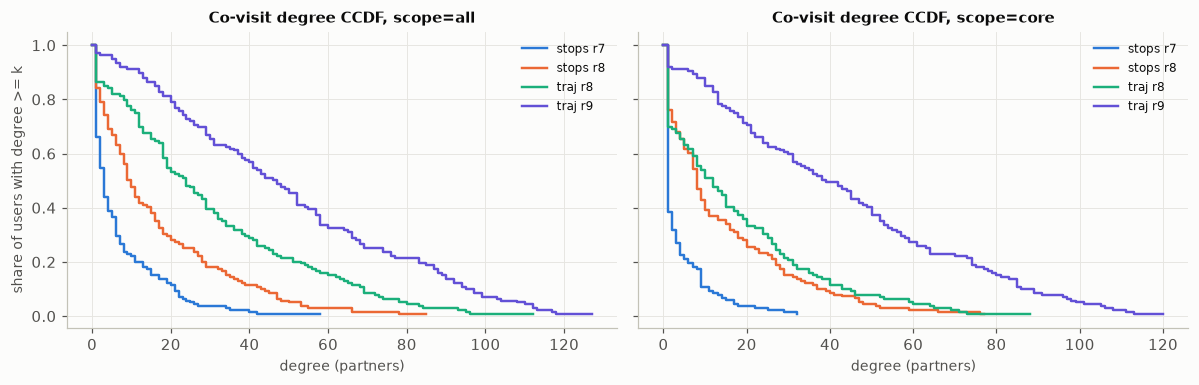

kind  res  max_pop  min_shared  edges  users_with_partner  deg_med
stop    8        5           1   1027                 127      9.0
stop    8        5           2    394                 100      2.0
stop    8        5           3    202                  72      1.0
stop    8       10           1   2201                 130     27.0
stop    8       10           2   1070                 117      9.0
stop    8       10           3    618                 105      4.0
stop    8       20           1   3492                 136     47.0
stop    8       20           2   1888                 124     20.0
stop    8       20           3   1182                 113     10.0
traj    9        5           1   2371                 136     27.0
traj    9        5           2   1728                 128     18.0
traj    9        5           3   1432                 123     13.0
traj    9       10           1   4270                 137     60.0
traj    9       10           2   3399                 135     

In [14]:
def graph_for(uc, max_pop=10, min_shared=2):
    return E.covisit_graph(uc.u.values, uc.cell.values, max_pop=max_pop, min_shared=min_shared)
rows, GR = [], {}
for kind, res_l in (("stop", (7, 8, 9)), ("traj", (8, 9))):
    for scope in ("all", "core"):
        for r in res_l:
            uc = UC[(kind, r, scope)]; users = np.sort(uc.u.unique())
            ed = graph_for(uc); deg = E.degrees(ed, N_USERS, users); GR[(kind, r, scope)] = (ed, users, deg)
            pairs = len(users) * (len(users) - 1) / 2
            rows.append({"kind": kind, "res": r, "scope": scope, "users": len(users), "edges": len(ed), "density": round(len(ed) / max(pairs, 1), 3),
                         "users_with_partner": int((deg > 0).sum()), "share": round((deg > 0).mean(), 3), "deg_med": float(np.median(deg)), "deg_p90": float(np.percentile(deg, 90)), "deg_max": int(deg.max())})
print("edge = share >= 2 'rare' cells (visited by 2..10 users in scope); weight = sum 1/log(1+n_cell)")
print(pd.DataFrame(rows).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, scope in zip(ax, ("all", "core")):
    for (kind, r), c, lbl in (((("stop", 7)), BLUE, "stops r7"), ((("stop", 8)), ORANGE, "stops r8"), ((("traj", 8)), AQUA, "traj r8"), ((("traj", 9)), VIOLET, "traj r9")):
        deg = GR[(kind, r, scope)][2]; x = np.arange(0, deg.max() + 1)
        a.step(x, [(deg >= k).mean() for k in x], where="post", color=c, label=lbl)
    a.set(title=f"Co-visit degree CCDF, scope={scope}", xlabel="degree (partners)"); a.legend(loc="upper right")
ax[0].set_ylabel("share of users with degree >= k")
plt.tight_layout(); plt.show()
# sensitivity of the edge definition (stops r8 / traj r9, all scope)
rows = []
for key in (("stop", 8, "all"), ("traj", 9, "all")):
    uc = UC[key]; users = np.sort(uc.u.unique())
    for mp in (5, 10, 20):
        for ms in (1, 2, 3):
            ed = graph_for(uc, mp, ms); deg = E.degrees(ed, N_USERS, users)
            rows.append({"kind": key[0], "res": key[1], "max_pop": mp, "min_shared": ms, "edges": len(ed), "users_with_partner": int((deg > 0).sum()), "deg_med": float(np.median(deg))})
print(pd.DataFrame(rows).to_string(index=False))

## 5. Sampling regime (feeds the synthetic render)

within-file dt (s): quantiles 5/25/50/75/90/95/99: [ 1.  1.  2.  5.  5.  5. 20.]


dt==1: 0.312  ==2: 0.328  ==3: 0.051  ==5: 0.248  <=5: 0.964 | >10 s: 0.0143  >60 s: 0.00499  >300 s: 0.001651


per-user median dt (s) distribution:  {1.0: 32, 2.0: 50, 3.0: 12, 4.0: 5, 5.0: 44, 11.0: 1, 12.0: 2, 16.0: 2} ... users: 182


gaps (dt>60 s) per logged hour (hours = sum of dt<=300 s): 5.38 | share of elapsed in-file time spent inside dt>60 s gaps: 0.619
gap-length quantiles for dt>60 s (s) 25/50/75/90/99: [  100.   210.   439.  1751. 14769.]


    mode   steps  p10   p50   p90   p99  stationary<0.3m/s
    walk 1329563 0.17  1.13  2.67 11.39              0.155
    bike  773266 0.65  3.11  5.22 11.34              0.064
     bus 1196436 0.24  4.70 12.70 25.10              0.115
car/taxi  710895 0.62  8.53 20.71 32.57              0.070
    rail  809532 1.81 19.14 37.33 57.20              0.018
   other    7870 0.28  2.86 19.97 24.63              0.108


unlabelled+labelled step speed quantiles 50/90/99 (m/s): [ 3.8  20.75 38.94]


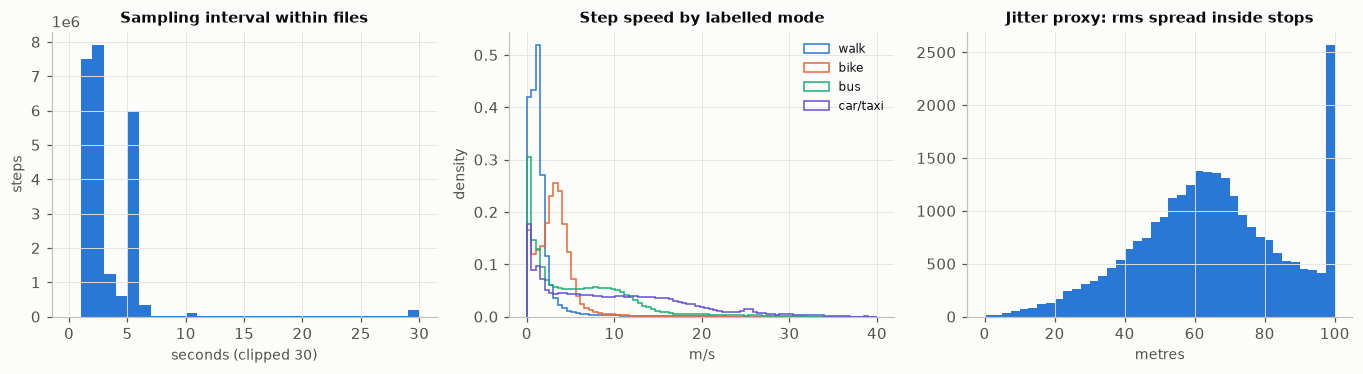

In [15]:
dtw = DT[SAMEFILE]; dd_ = D[SAMEFILE]
print("within-file dt (s): quantiles 5/25/50/75/90/95/99:", np.percentile(dtw, [5, 25, 50, 75, 90, 95, 99]))
print("dt==1: %.3f  ==2: %.3f  ==3: %.3f  ==5: %.3f  <=5: %.3f | >10 s: %.4f  >60 s: %.5f  >300 s: %.6f" % tuple(
      [(dtw == k).mean() for k in (1, 2, 3, 5)] + [(dtw <= 5).mean(), (dtw > 10).mean(), (dtw > 60).mean(), (dtw > 300).mean()]))
ud = pd.DataFrame({"u": U[1:][SAMEFILE], "dt": dtw}).groupby("u").dt.median()
print("per-user median dt (s) distribution: ", ud.value_counts().sort_index().head(8).to_dict(), "... users:", len(ud))
logged_h = dtw[dtw <= 300].sum() / 3600
print("gaps (dt>60 s) per logged hour (hours = sum of dt<=300 s): %.2f | share of elapsed in-file time spent inside dt>60 s gaps: %.3f" % ((dtw > 60).sum() / logged_h, dtw[dtw > 60].sum() / dtw.sum()))
print("gap-length quantiles for dt>60 s (s) 25/50/75/90/99:", np.percentile(dtw[dtw > 60], [25, 50, 75, 90, 99]).round(0))
spd = np.where(dtw > 0, dd_ / np.maximum(dtw, 1e-9), np.nan)
mc = MODECODE[:-1][SAMEFILE]; okm = (mc >= 0) & (dtw >= 1) & (dtw <= 60) & np.isfinite(spd) & (spd < 70)
rows = []
for k, m in enumerate(MODES):
    s_ = spd[okm & (mc == k)]
    if len(s_) > 100: rows.append({"mode": m, "steps": len(s_), "p10": round(np.percentile(s_, 10), 2), "p50": round(np.percentile(s_, 50), 2), "p90": round(np.percentile(s_, 90), 2), "p99": round(np.percentile(s_, 99), 2), "stationary<0.3m/s": round((s_ < .3).mean(), 3)})
print(pd.DataFrame(rows).to_string(index=False))
allm = okm | ((mc < 0) & (dtw >= 1) & (dtw <= 60) & np.isfinite(spd) & (spd < 70))
print("unlabelled+labelled step speed quantiles 50/90/99 (m/s):", np.percentile(spd[allm], [50, 90, 99]).round(2))
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
ax[0].hist(np.clip(dtw, 0, 30), bins=np.arange(0, 31, 1), color=BLUE); ax[0].set(title="Sampling interval within files", xlabel="seconds (clipped 30)", ylabel="steps")
bins = np.linspace(0, 40, 80)
for k, c in zip((0, 1, 2, 3), CAT):
    s_ = spd[okm & (mc == k)]
    if len(s_) > 100: ax[1].hist(s_, bins=bins, histtype="step", color=c, density=True, label=MODES[k])
ax[1].set(title="Step speed by labelled mode", xlabel="m/s", ylabel="density"); ax[1].legend()
ax[2].hist(st.rms.clip(upper=100), bins=40, color=BLUE); ax[2].set(title="Jitter proxy: rms spread inside stops", xlabel="metres"); plt.tight_layout(); plt.show()

## 6. Split-half reliability (label-free baseline)

Each qualifying user's real outings are split into two halves: by time (first half / second half of their
outings) and at random (seeded). Places = stop cells; segments proxy = traversed cells. Eligible users need
at least 2 outings with a stop in each half (place metrics) or any incidence in both halves (graph metrics).

In [16]:
rngs = np.random.default_rng(SEED)
qo = og[og.qual & og.u.isin(QU)].copy()
qo["rank"] = qo.groupby("u").cumcount(); qo["n_u"] = qo.groupby("u").u.transform("size")
qo["half_time"] = (qo["rank"] >= qo.n_u / 2).astype(int)
qo["rk"] = qo.assign(r=rngs.random(len(qo))).groupby("u").r.rank(method="first")
qo["half_rand"] = (qo.rk > qo.n_u / 2).astype(int)
HALF = {"time": qo.half_time, "random": qo.half_rand}
def place_reliability(res, split):
    inc = INC[("stop", res, "all")]; inc = inc[inc.oid.isin(qo.index)].copy()
    inc["u"] = u_of_oid[inc.oid.values]; inc["h"] = HALF[split].reindex(inc.oid.values).values
    a, b = {}, {}
    for (u, h), s_ in inc.groupby(["u", "h"]):
        (a if h == 0 else b)[u] = s_
    users = [u for u in a if u in b and a[u].oid.nunique() >= 2 and b[u].oid.nunique() >= 2]
    jac, jt3, cov, base = [], [], [], []
    setA = {u: set(a[u].cell) for u in users}
    for k, u in enumerate(users):
        A, B = setA[u], set(b[u].cell)
        jac.append(E.jaccard(A, B))
        ta = set(a[u].cell.value_counts().index[:3]); tb = set(b[u].cell.value_counts().index[:3]); jt3.append(E.jaccard(ta, tb))
        cov.append(b[u].cell.isin(A).mean())
        other = setA[users[(k + 1) % len(users)]]; base.append(b[u].cell.isin(other).mean())
    return {"res": res, "split": split, "eligible_users": len(users), "jaccard_place_sets": round(np.median(jac), 3), "jaccard_top3": round(np.median(jt3), 3),
            "B_stops_in_A_set": round(np.mean(cov), 3), "same_for_other_user": round(np.mean(base), 3)}
print(pd.DataFrame([place_reliability(r, s) for r in (7, 8, 9) for s in ("time", "random")]).to_string(index=False))

 res  split  eligible_users  jaccard_place_sets  jaccard_top3  B_stops_in_A_set  same_for_other_user
   7   time             124               0.200           0.5             0.551                0.298
   7 random             126               0.281           0.5             0.642                0.323
   8   time             124               0.143           0.2             0.431                0.154
   8 random             126               0.205           0.5             0.515                0.167
   9   time             124               0.107           0.2             0.321                0.080
   9 random             126               0.138           0.2             0.409                0.081


In [17]:
def graph_reliability(kind, res, split, scope="all"):
    inc = INC[(kind, res, scope)]; inc = inc[inc.oid.isin(qo.index)].copy()
    inc["u"] = u_of_oid[inc.oid.values]; inc["h"] = HALF[split].reindex(inc.oid.values).values
    both = set(inc[inc.h == 0].u) & set(inc[inc.h == 1].u)
    inc = inc[inc.u.isin(both)]
    gs = [E.covisit_graph(inc[inc.h == h].u.values, inc[inc.h == h].cell.values, max_pop=10, min_shared=2) for h in (0, 1)]
    ea, eb = (set(zip(g.a, g.b)) for g in gs)
    n = len(both); pairs = n * (n - 1) / 2
    inter = len(ea & eb)
    return {"kind": kind, "res": res, "split": split, "users": n, "edges_A": len(ea), "edges_B": len(eb), "edge_jaccard": round(inter / max(len(ea | eb), 1), 3),
            "P(edge in B | edge in A)": round(inter / max(len(ea), 1), 3), "density_B": round(len(eb) / pairs, 3), "lift": round((inter / max(len(ea), 1)) / max(len(eb) / pairs, 1e-9), 1)}
print(pd.DataFrame([graph_reliability(k, r, s) for k, r in (("stop", 7), ("stop", 8), ("traj", 8), ("traj", 9)) for s in ("time", "random")]).to_string(index=False))

kind  res  split  users  edges_A  edges_B  edge_jaccard  P(edge in B | edge in A)  density_B  lift
stop    7   time    132      299      329         0.284                     0.465      0.038  12.2
stop    7 random    134      365      312         0.294                     0.422      0.035  12.1
stop    8   time    132      588      539         0.292                     0.434      0.062   7.0
stop    8 random    134      640      626         0.328                     0.489      0.070   7.0
traj    8   time    139     1621     1485         0.362                     0.509      0.155   3.3
traj    8 random    139     1598     1687         0.436                     0.625      0.176   3.6
traj    9   time    139     2953     2692         0.458                     0.600      0.281   2.1
traj    9 random    139     2993     3022         0.542                     0.706      0.315   2.2


## 7. Caps: how many outings / places / segments per user

In [18]:
q2 = og[og.qual & og.u.isin(QU)]
pu = pd.DataFrame({"real_outings": q2.groupby("u").size(), "active_days": uq.loc[QU, "active_days"]})
for r in (7, 8, 9): pu[f"stop_cells_r{r}"] = UC[("stop", r, "all")].groupby("u").cell.nunique()
for r in (7, 8, 9): pu[f"traj_cells_r{r}"] = UC[("traj", r, "all")].groupby("u").cell.nunique()
pu = pu.fillna(0)
print(pu.describe(percentiles=[.5, .75, .9, .95, .99]).round(0).T[["50%", "75%", "90%", "95%", "99%", "max"]])
def kept(vals, cap): return float(np.minimum(vals, cap).sum() / vals.sum())
rows = []
for col, caps in (("real_outings", (20, 50, 100, 200)), ("stop_cells_r8", (10, 20, 50, 100)), ("stop_cells_r9", (10, 20, 50, 100)), ("traj_cells_r7", (100, 200, 500, 1000)), ("traj_cells_r8", (200, 500, 1000, 2000)), ("traj_cells_r9", (200, 500, 1000, 2000))):
    for c in caps: rows.append({"quantity": col, "cap": c, "share_users_capped": round(float((pu[col] > c).mean()), 3), "share_incidences_kept": round(kept(pu[col].values, c), 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("stops per outing: p50/p90/p99 =", np.percentile(cnt, [50, 90, 99]))

                 50%     75%      90%      95%      99%      max
real_outings    45.0   125.0    280.0    515.0   1367.0   2312.0
active_days     36.0    82.0    174.0    255.0    777.0   1251.0
stop_cells_r7   15.0    37.0     76.0    116.0    296.0    425.0
stop_cells_r8   25.0    55.0    127.0    160.0    521.0    608.0
stop_cells_r9   34.0    80.0    171.0    258.0    734.0    925.0
traj_cells_r7  124.0   572.0   1395.0   1870.0   6746.0   7705.0
traj_cells_r8  362.0  1634.0   3981.0   5007.0  17589.0  20528.0
traj_cells_r9  909.0  4078.0  10130.0  13115.0  43525.0  51360.0
     quantity  cap  share_users_capped  share_incidences_kept
 real_outings   20               0.770                  0.138
 real_outings   50               0.482                  0.274
 real_outings  100               0.324                  0.427
 real_outings  200               0.151                  0.588
stop_cells_r8   10               0.799                  0.176
stop_cells_r8   20               0.540     

## 8. Recommended public parameters

"Data-informed" = the value was chosen after looking at real GeoLife numbers in this notebook, so it counts as tuning for the ledger caveat (public-parameter selection on the sensitive data, not accounted in epsilon).

| Parameter | Recommendation | One-line justification | Data-informed? |
|---|---|---|---|
| Local time | UTC+8; artifact must state its hour convention | GeoLife is GMT; commute-like peaks only appear at 08h and 17-18h local | No (fact) |
| Outing gap | **2 h** (7200 s), across file boundaries | 84% of consecutive files are >2 h apart, but 0.22 in-file gaps/file exceed 2 h (signal loss indoors); 2 h keeps 19.7k outings, med 45 min / 9 km | Yes |
| Real outing | duration >= 5 min and length >= 500 m | drops 5% of fragments; no effect on the heavy tail | Yes (mild) |
| Min activity | **>= 10 real outings on >= 5 local days** | keeps 139 of 182 users and 99.0% of real outings; users below that cannot be split into halves | Yes |
| Stop rule | **200 m radius, 10 min dwell** | 1.38 stops per real outing, 49% of outings have a stop, median dwell 22 min; 100 m/5 min is dominated by jitter and short pauses | Yes |
| Start/end visits | add outing start and end as visits | dwell rule misses destinations where logging ends | No |
| Time bins | place/category x time: **4 time-of-day x weekday/weekend (8 bins)**; global outing-start and stop tables may use 24 h x 2 | 8 bins keep about 3.1k stops/bin overall and 28% of user-keys in cell-bins with >=10 users (24 h x 2: 17%) | Yes |
| Place hierarchy | H3 **6 -> 7 -> 8** for stop places; stop at 8 | cells with >=10 users saturate at ~100 (res 7: 81, 8: 100, 9: 102) while the incidence share in them falls 41% -> 26% -> 15% | Yes |
| Segment hierarchy | H3 **6 -> 7 -> 8**, optional refine to 9 / matched road segments under busy parents | traversed cells: share of incidences in >=10-user cells is flat across res 6-9 (32% -> 30%), so resolution is cheap; res 8 has 3.4k such cells | Yes |
| Cap: outings per user | **100** | p50 45, p90 280; cap touches 32% of users, keeps 43% of outings | Yes |
| Cap: distinct places per user | **50 stop cells at res 8** | p50 25, p90 127; caps 26% of users, keeps 53% of place incidences | Yes |
| Cap: distinct segments per user | **1000 traversed res-8 cells** (re-derive on matched segments in T2) | p50 362, p90 3981; caps 30% of users, keeps 33% of incidences; heavy-user tail is extreme | Yes |
| Co-visit edge | share >= 2 rare cells (2..10 users in scope), IDF weights; stops at res 8 | 84% of users get a partner, split-half edge lift ~7x; the traversal graph at res 9 links 35% of all pairs and is too dense to discriminate | Yes |
| Scope | keep all of Beijing; treat the core box (116.2-116.6E, 39.8-40.1N) as dense regime | outside the core overlap is far sparser | Yes |
